## 1. Install libraries and load the dataset

In [1]:
!pip install -q jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 77.0 MB/s eta 0:00:00


In [2]:
import os, re, glob, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import jiwer
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from IPython.display import Audio, display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ---- Settings ----
EPOCHS = 20
BATCH_SIZE = 64
LR = 1e-3
STT_SAMPLES = 200      # number of test recordings used to evaluate Speech-to-Text
SR = 8000              # sampling rate of the dataset (8 kHz)
N_MELS, MAX_FRAMES = 64, 80
WORDS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]

Using device: cuda


In [3]:
# Free Spoken Digit Dataset: recordings of spoken digits 0-9 (files named digit_speaker_index.wav)
if not os.path.exists("free-spoken-digit-dataset"):
    !git clone -q --depth 1 https://github.com/Jakobovski/free-spoken-digit-dataset.git

files = sorted(glob.glob("free-spoken-digit-dataset/recordings/*.wav"))
labels = np.array([int(os.path.basename(f).split("_")[0]) for f in files])
speakers = sorted(set(os.path.basename(f).split("_")[1] for f in files))

waves = [librosa.load(f, sr=SR)[0] for f in files]       # raw waveforms (8 kHz)
durations = np.array([len(w) / SR for w in waves])

print("Recordings:", len(files))
print("Speakers  :", speakers)
print("Classes   :", WORDS)
print("Recordings per digit:", np.bincount(labels))
print(f"Duration  : min {durations.min():.2f}s | mean {durations.mean():.2f}s | max {durations.max():.2f}s")

Recordings: 3000
Speakers  : ['george', 'jackson', 'lucas', 'nicolas', 'theo', 'yweweler']
Classes   : ['zero', 'one', 'two', 'three', 'four', 'five', 'six', 'seven', 'eight', 'nine']
Recordings per digit: [300 300 300 300 300 300 300 300 300 300]
Duration  : min 0.14s | mean 0.44s | max 2.28s


## 2. Visualize waveforms and mel spectrograms

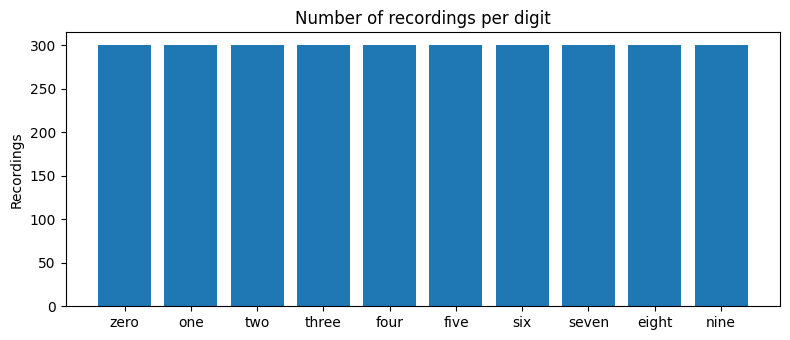

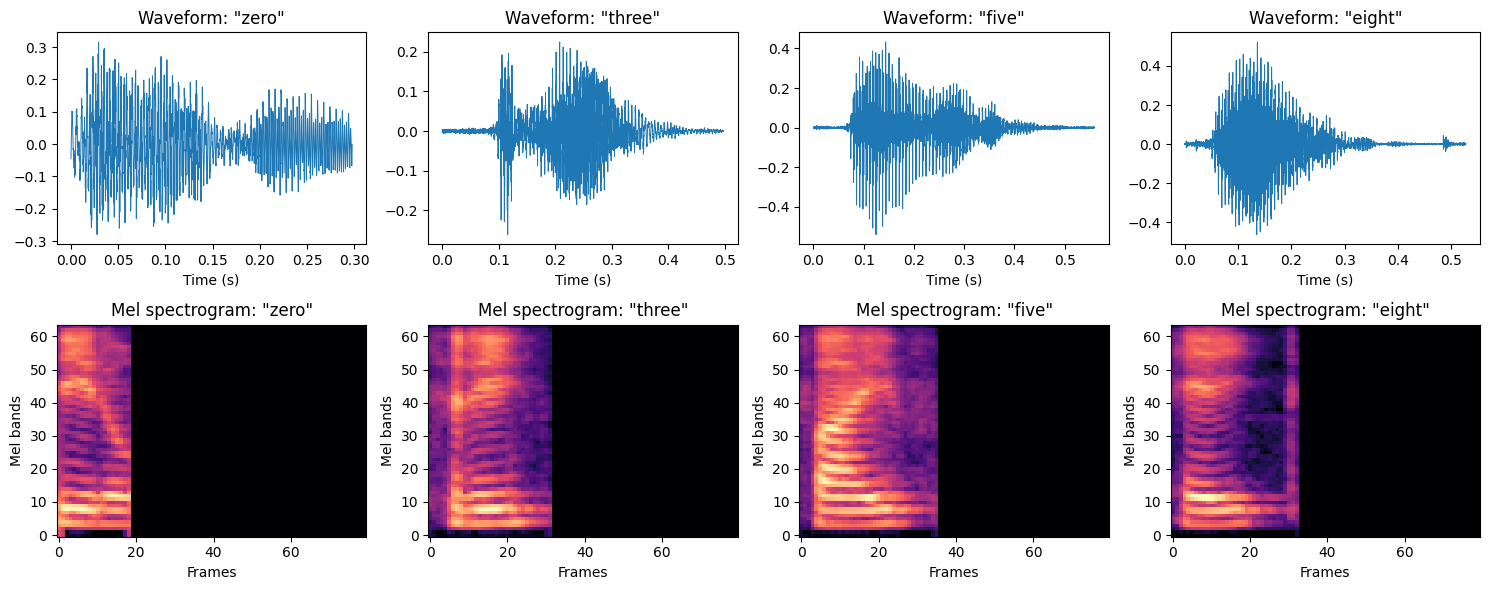

Listen to a sample:


In [4]:
def to_mel(y):
    """Waveform -> log-mel spectrogram of fixed size (N_MELS x MAX_FRAMES), scaled to about [-1, 1]."""
    m = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=512, hop_length=128, n_mels=N_MELS, fmax=SR // 2)
    m = librosa.power_to_db(m, ref=np.max)                      # range [-80, 0] dB
    if m.shape[1] < MAX_FRAMES:
        m = np.pad(m, ((0, 0), (0, MAX_FRAMES - m.shape[1])), constant_values=-80.0)
    return ((m[:, :MAX_FRAMES] + 40.0) / 40.0).astype(np.float32)

plt.figure(figsize=(8, 3.5))
plt.bar(WORDS, np.bincount(labels), color="tab:blue")
plt.title("Number of recordings per digit"); plt.ylabel("Recordings"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, d in enumerate([0, 3, 5, 8]):
    i = int(np.where(labels == d)[0][0])
    t = np.arange(len(waves[i])) / SR
    axes[0, j].plot(t, waves[i], lw=0.7); axes[0, j].set_title(f'Waveform: "{WORDS[d]}"'); axes[0, j].set_xlabel("Time (s)")
    axes[1, j].imshow(to_mel(waves[i]), origin="lower", aspect="auto", cmap="magma")
    axes[1, j].set_title(f'Mel spectrogram: "{WORDS[d]}"'); axes[1, j].set_xlabel("Frames"); axes[1, j].set_ylabel("Mel bands")
plt.tight_layout(); plt.show()

print("Listen to a sample:")
display(Audio(waves[0], rate=SR))

## 3. CNN audio classifier

In [5]:
# Features and stratified split: 70% train / 15% validation / 15% test
X = torch.tensor(np.stack([to_mel(w) for w in waves])).unsqueeze(1)     # (N, 1, 64, 80)
y = torch.tensor(labels)
idx = np.arange(len(labels))
tr_val_idx, test_idx = train_test_split(idx, test_size=0.15, stratify=labels, random_state=SEED)
train_idx, val_idx = train_test_split(tr_val_idx, test_size=0.1765, stratify=labels[tr_val_idx], random_state=SEED)

def loader(ix, shuffle):
    return DataLoader(TensorDataset(X[ix], y[ix]), BATCH_SIZE, shuffle=shuffle)
train_dl, val_dl, test_dl = loader(train_idx, True), loader(val_idx, False), loader(test_idx, False)
print("Input shape:", tuple(X.shape[1:]))
print(f"Train: {len(train_idx)} | Validation: {len(val_idx)} | Test: {len(test_idx)}")

Input shape: (1, 64, 80)
Train: 2099 | Validation: 451 | Test: 450


In [6]:
class AudioCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

cnn = AudioCNN().to(device)
print(cnn)
print("Trainable parameters:", f"{sum(p.numel() for p in cnn.parameters() if p.requires_grad):,}")

AudioCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), 

In [7]:
def run_epoch(model, dl, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total / n, correct / n

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn.parameters(), lr=LR)
hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc, best_state, start = 0.0, None, time.time()
for ep in range(EPOCHS):
    tl, ta = run_epoch(cnn, train_dl, criterion, optimizer)
    vl, va = run_epoch(cnn, val_dl, criterion)
    for k, v in zip(hist, [tl, ta, vl, va]): hist[k].append(v)
    if va > best_acc:
        best_acc, best_state = va, copy.deepcopy(cnn.state_dict())
    print(f"Epoch {ep+1:2d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
cnn.load_state_dict(best_state)       # keep the best model (highest validation accuracy)
print(f"\nTraining time: {time.time() - start:.1f} s | best validation accuracy: {best_acc:.4f}")

Epoch  1/20 | train loss 2.0370 acc 0.2878 | val loss 2.0258 acc 0.3126
Epoch  2/20 | train loss 1.5376 acc 0.5479 | val loss 1.3993 acc 0.6297
Epoch  3/20 | train loss 1.1420 acc 0.7213 | val loss 1.1193 acc 0.6785
Epoch  4/20 | train loss 0.8076 acc 0.8347 | val loss 0.7580 acc 0.8559
Epoch  5/20 | train loss 0.5873 acc 0.8919 | val loss 0.5885 acc 0.8603
Epoch  6/20 | train loss 0.4503 acc 0.9223 | val loss 0.5065 acc 0.9002
Epoch  7/20 | train loss 0.3547 acc 0.9409 | val loss 0.3626 acc 0.9401
Epoch  8/20 | train loss 0.2752 acc 0.9595 | val loss 0.3345 acc 0.9113
Epoch  9/20 | train loss 0.2260 acc 0.9676 | val loss 0.2770 acc 0.9335
Epoch 10/20 | train loss 0.1859 acc 0.9743 | val loss 0.2043 acc 0.9623
Epoch 11/20 | train loss 0.1651 acc 0.9747 | val loss 0.2762 acc 0.9379
Epoch 12/20 | train loss 0.1357 acc 0.9819 | val loss 0.1758 acc 0.9667
Epoch 13/20 | train loss 0.1203 acc 0.9833 | val loss 0.1605 acc 0.9667
Epoch 14/20 | train loss 0.0985 acc 0.9876 | val loss 0.1994 acc

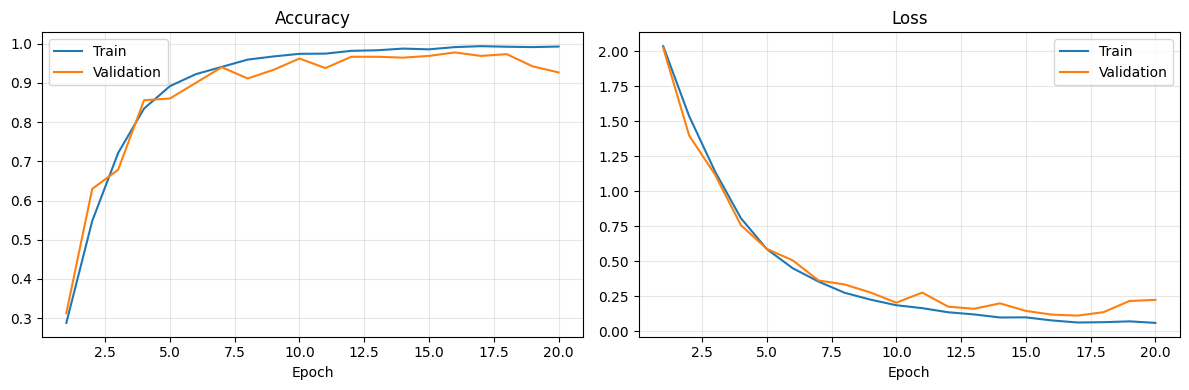

In [8]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, hist["train_acc"], label="Train"); ax[0].plot(ep, hist["val_acc"], label="Validation"); ax[0].set_title("Accuracy")
ax[1].plot(ep, hist["train_loss"], label="Train"); ax[1].plot(ep, hist["val_loss"], label="Validation"); ax[1].set_title("Loss")
for a in ax: a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

### Evaluate the CNN on the test set

Test accuracy : 0.9756
Precision (macro): 0.9772 | Recall (macro): 0.9756 | F1 (macro): 0.9752

              precision    recall  f1-score   support

        zero      0.978     1.000     0.989        45
         one      1.000     0.844     0.916        45
         two      1.000     1.000     1.000        45
       three      0.938     1.000     0.968        45
        four      1.000     1.000     1.000        45
        five      0.918     1.000     0.957        45
         six      1.000     0.956     0.977        45
       seven      1.000     0.978     0.989        45
       eight      1.000     0.978     0.989        45
        nine      0.938     1.000     0.968        45

    accuracy                          0.976       450
   macro avg      0.977     0.976     0.975       450
weighted avg      0.977     0.976     0.975       450



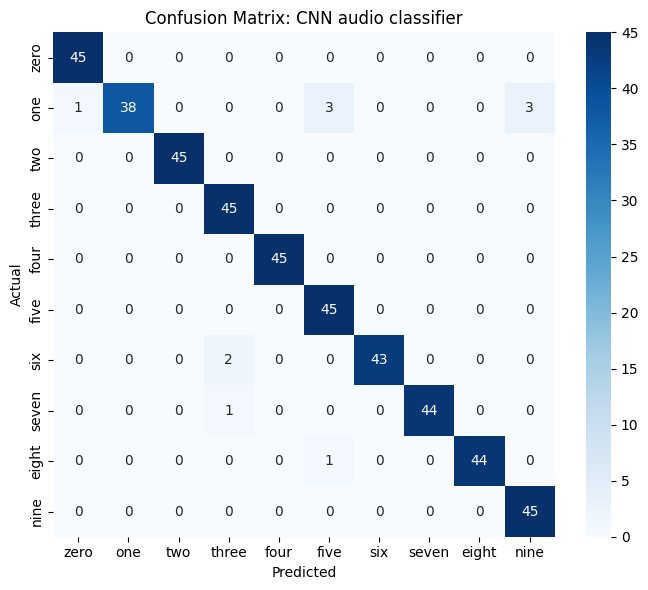

In [9]:
@torch.no_grad()
def predict(model, dl):
    model.eval()
    ps = []
    for xb, _ in dl:
        ps.append(model(xb.to(device)).argmax(1).cpu())
    return torch.cat(ps).numpy()

y_test = labels[test_idx]
t0 = time.time()
y_pred = predict(cnn, test_dl)
cnn_ms = 1000 * (time.time() - t0) / len(y_test)

cnn_acc = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
print(f"Test accuracy : {cnn_acc:.4f}")
print(f"Precision (macro): {p:.4f} | Recall (macro): {r:.4f} | F1 (macro): {f1:.4f}\n")
print(classification_report(y_test, y_pred, target_names=WORDS, digits=3))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=WORDS, yticklabels=WORDS)
plt.title("Confusion Matrix: CNN audio classifier"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

## 4. Speech-to-Text (Whisper)

In [10]:
from transformers import pipeline

stt = pipeline("automatic-speech-recognition", model="openai/whisper-tiny.en", device=0 if device.type == "cuda" else -1)

NUM2WORD = {str(i): w for i, w in enumerate(WORDS)}
HOMOPHONES = {"oh": "zero", "won": "one", "to": "two", "too": "two", "for": "four", "fore": "four", "ate": "eight"}

def normalize(text):
    """Lower-case, remove punctuation, write digits as words (7 -> seven) and map common homophones."""
    text = re.sub(r"[^a-z0-9 ]", "", text.lower().replace("-", " "))
    return " ".join(NUM2WORD.get(w, HOMOPHONES.get(w, w)) for w in text.split())

def to_16k(w):
    return librosa.resample(w, orig_sr=SR, target_sr=16000).astype(np.float32)   # Whisper needs 16 kHz

def transcribe(wave_list, batch_size=16):
    outs = stt([{"raw": to_16k(w), "sampling_rate": 16000} for w in wave_list], batch_size=batch_size)
    return [o["text"] for o in outs]

config.json:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/1.62k [00:00<?, ?B/s]

...

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.83k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

In [11]:
stt_idx = test_idx[:STT_SAMPLES]
t0 = time.time()
raw_text = transcribe([waves[i] for i in stt_idx])
stt_ms = 1000 * (time.time() - t0) / len(stt_idx)

refs = [WORDS[labels[i]] for i in stt_idx]
hyps = [normalize(t) for t in raw_text]

wer = jiwer.wer(refs, hyps)
cer = jiwer.cer(refs, hyps)
stt_digits = np.array([next((WORDS.index(w) for w in h.split() if w in WORDS), -1) for h in hyps])
stt_acc = accuracy_score(labels[stt_idx], stt_digits)
cnn_acc_subset = accuracy_score(labels[stt_idx], predict(cnn, loader(stt_idx, False)))

print(f"Whisper on {len(stt_idx)} test recordings")
print(f"Word Error Rate (WER)     : {wer:.4f}")
print(f"Character Error Rate (CER): {cer:.4f}")
print(f"Digit recognition accuracy: {stt_acc:.4f}   (CNN on the same recordings: {cnn_acc_subset:.4f})")
print(f"Speed: {stt_ms:.1f} ms per recording\n")

print(pd.DataFrame({"Reference": refs[:12], "Whisper output": [t.strip() for t in raw_text[:12]], "Normalized": hyps[:12]}).to_string(index=False))

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Whisper on 200 test recordings
Word Error Rate (WER)     : 0.6250
Character Error Rate (CER): 0.5934
Digit recognition accuracy: 0.5800   (CNN on the same recordings: 0.9800)
Speed: 64.3 ms per recording

Reference       Whisper output          Normalized
     nine                   9.                nine
    three               Three.               three
      one                 one.                 one
      one                 one.                 one
     zero                Zero.                zero
     five                 Bye.                 bye
    seven Thank you very much. thank you very much
    seven                   7.               seven
     five                five.                five
     five                 Bye.                 bye
      two           Thank you.           thank you
    eight                 Hey.                 hey


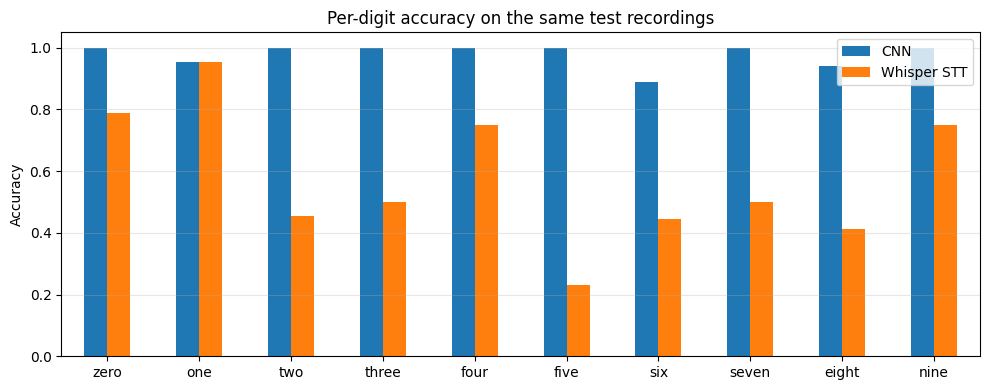

,CNN,Whisper STT
zero,1.000,0.789
one,0.955,0.955
two,1.000,0.455
three,1.000,0.500
four,1.000,0.750
five,1.000,0.231
six,0.889,0.444
seven,1.000,0.500
eight,0.941,0.412
nine,1.000,0.750


In [12]:
# Per-digit accuracy: CNN vs Whisper on the same recordings
cnn_pred_subset = predict(cnn, loader(stt_idx, False))
true_sub = labels[stt_idx]
per_digit = pd.DataFrame({
    "CNN": [np.mean(cnn_pred_subset[true_sub == d] == d) for d in range(10)],
    "Whisper STT": [np.mean(stt_digits[true_sub == d] == d) for d in range(10)]}, index=WORDS)
per_digit.plot.bar(figsize=(10, 4), rot=0, ylim=(0, 1.05), title="Per-digit accuracy on the same test recordings")
plt.ylabel("Accuracy"); plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()
per_digit.round(3)

## 5. Text-to-Speech (MMS-TTS)

In [13]:
from transformers import VitsModel, AutoTokenizer

tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-eng")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-eng").to(device).eval()
TTS_SR = tts_model.config.sampling_rate

def synthesize(text):
    inputs = tts_tok(text, return_tensors="pt").to(device)
    with torch.no_grad():
        wav = tts_model(**inputs).waveform
    return wav.squeeze().cpu().numpy().astype(np.float32)

print("TTS sampling rate:", TTS_SR, "Hz")
display(Audio(synthesize("the predicted digit is seven"), rate=TTS_SR))

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/47.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  145MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

TTS sampling rate: 16000 Hz


In [14]:
# TTS evaluation: synthesize text, transcribe it again with Whisper (round trip) and compute WER
texts = WORDS + [f"the predicted digit is {w}" for w in WORDS]
torch.manual_seed(SEED)
synth, audio_sec, t0 = [], 0.0, time.time()
for t in texts:
    a = synthesize(t)
    synth.append(a); audio_sec += len(a) / TTS_SR
rtf = (time.time() - t0) / audio_sec          # real-time factor (< 1 means faster than real time)

round_trip = [t["text"] for t in stt([{"raw": a, "sampling_rate": TTS_SR} for a in synth], batch_size=8)]
rt_norm = [normalize(t) for t in round_trip]
ref_norm = [normalize(t) for t in texts]

tts_wer_words = jiwer.wer(ref_norm[:10], rt_norm[:10])
tts_wer_sent = jiwer.wer(ref_norm[10:], rt_norm[10:])
tts_wer_all = jiwer.wer(ref_norm, rt_norm)

print(f"Round-trip WER (single words) : {tts_wer_words:.4f}")
print(f"Round-trip WER (sentences)    : {tts_wer_sent:.4f}")
print(f"Round-trip WER (all)          : {tts_wer_all:.4f}")
print(f"Real-time factor              : {rtf:.3f}  (synthesis time / audio duration)\n")
print(pd.DataFrame({"Input text": texts, "Whisper heard": [t.strip() for t in round_trip]}).to_string(index=False))

Round-trip WER (single words) : 1.0000
Round-trip WER (sentences)    : 0.1800
Round-trip WER (all)          : 0.3167
Real-time factor              : 0.098  (synthesis time / audio duration)

                  Input text                  Whisper heard
                        zero                          Firo.
                         one                            the
                         two                           Yep.
                       three                         Three.
                        four                        Howard.
                        five                         Thiof.
                         six                          Here.
                       seven                           HEN!
                       eight                         Eight.
                        nine           Thanks for watching!
 the predicted digit is zero The predicted dignity is zero.
  the predicted digit is one      The predicted digit is 1.
  the predicted digit is two 

## 6. Complete application: audio → classification → STT → TTS

In [15]:
def run_pipeline(index):
    """Takes one recording and (1) classifies it with the CNN, (2) transcribes it with Whisper,
    (3) speaks the result with TTS and (4) checks the spoken answer by transcribing it again."""
    w = waves[index]
    pred = int(predict(cnn, loader(np.array([index]), False))[0])
    heard = transcribe([w])[0].strip()
    reply = f"the predicted digit is {WORDS[pred]}"
    speech = synthesize(reply)
    check = stt({"raw": speech, "sampling_rate": TTS_SR})["text"].strip()
    print(f"Actual digit      : {WORDS[labels[index]]}")
    print(f"CNN prediction    : {WORDS[pred]}")
    print(f"Whisper transcript: {heard}")
    print(f"TTS reply text    : {reply}")
    print(f"Whisper check of TTS audio: {check}")
    print("Input audio:");  display(Audio(w, rate=SR))
    print("TTS reply:");    display(Audio(speech, rate=TTS_SR))

for i in test_idx[:3]:
    print("-" * 60)
    run_pipeline(int(i))

------------------------------------------------------------
Actual digit      : nine
CNN prediction    : nine
Whisper transcript: 9.
TTS reply text    : the predicted digit is nine
Whisper check of TTS audio: The predicate did it is nine.
Input audio:


TTS reply:


------------------------------------------------------------
Actual digit      : three
CNN prediction    : three
Whisper transcript: Three.
TTS reply text    : the predicted digit is three
Whisper check of TTS audio: The predicted date is 3.
Input audio:


TTS reply:


------------------------------------------------------------
Actual digit      : one
CNN prediction    : one
Whisper transcript: one.
TTS reply text    : the predicted digit is one
Whisper check of TTS audio: The predicted dig it is one.
Input audio:


TTS reply:


## 7. Performance summary

In [16]:
summary = pd.DataFrame([
    ["Audio classification (CNN)", "Test accuracy", f"{cnn_acc:.4f}"],
    ["Audio classification (CNN)", "Macro F1-score", f"{f1:.4f}"],
    ["Audio classification (CNN)", "Inference time (ms/recording)", f"{cnn_ms:.2f}"],
    ["Speech-to-Text (Whisper)", "Word Error Rate (WER)", f"{wer:.4f}"],
    ["Speech-to-Text (Whisper)", "Character Error Rate (CER)", f"{cer:.4f}"],
    ["Speech-to-Text (Whisper)", "Digit recognition accuracy", f"{stt_acc:.4f}"],
    ["Speech-to-Text (Whisper)", "Time (ms/recording)", f"{stt_ms:.1f}"],
    ["Text-to-Speech (MMS-TTS)", "Round-trip WER (all texts)", f"{tts_wer_all:.4f}"],
    ["Text-to-Speech (MMS-TTS)", "Real-time factor", f"{rtf:.3f}"],
], columns=["Component", "Metric", "Value"])
summary

,Component,Metric,Value
0,Audio classification (CNN),Test accuracy,0.9756
1,Audio classification (CNN),Macro F1-score,0.9752
2,Audio classification (CNN),Inference time (ms/recording),0.08
3,Speech-to-Text (Whisper),Word Error Rate (WER),0.6250
4,Speech-to-Text (Whisper),Character Error Rate (CER),0.5934
5,Speech-to-Text (Whisper),Digit recognition accuracy,0.5800
6,Speech-to-Text (Whisper),Time (ms/recording),64.3
7,Text-to-Speech (MMS-TTS),Round-trip WER (all texts),0.3167
8,Text-to-Speech (MMS-TTS),Real-time factor,0.098
